[[1, np.float64(0.5780762374649757), np.float64(0.4615360679920366)],
 [2, np.float64(0.050114754746068184), np.float64(0.03000871514194556)],
 [3, np.float64(0.038038552066369136), np.float64(0.015184989984894563)],
 [4, np.float64(0.03002891835062756), np.float64(0.005993772102785159)]]

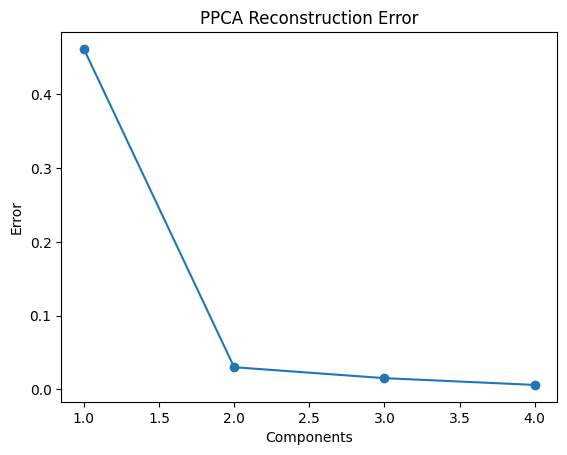

Estimated Noise Variance: 0.050114754746068184
Generated Samples:
[[-1.31622137  0.11173663 -0.95277833 -0.65428758 -1.24225965]
 [ 1.45007929  0.34770342  1.03042685  0.32224166  1.39457941]
 [-1.77804153 -0.02706687 -0.65972695 -1.04806692 -1.13852244]
 [-0.54705821  0.68289169 -0.61352668 -0.94742287 -0.52518271]
 [-1.25568077  2.21607223  0.22703914 -2.41371741 -1.39745647]]


In [10]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

np.random.seed(42)

z = np.random.randn(500, 2)

W = np.array([
    [2, 0],
    [0, 1],
    [1, 1],
    [0.5, -1],
    [1.5, 0.2]
])

X = z @ W.T + 0.3*np.random.randn(500, 5)
X = (X-X.mean(0))/X.std(0)

results = []

for k in [1, 2, 3, 4]:

    pca = PCA(n_components=k).fit(X)

    rec = pca.inverse_transform(
        pca.transform(X)
    )

    error = np.mean((X-rec)**2)

    results.append([
        k, pca.noise_variance_, error
    ])

display(results)

plt.plot(
    [r[0] for r in results],
    [r[2] for r in results],
    marker="o"
)

plt.title("PPCA Reconstruction Error")
plt.xlabel("Components")
plt.ylabel("Error")
plt.show()

pca = PCA(n_components=2).fit(X)

print("Estimated Noise Variance:",
      pca.noise_variance_)

samples = np.random.multivariate_normal(
    pca.mean_, pca.get_covariance(), 5
)

print("Generated Samples:")
print(samples)
